In [6]:
import os
import sys

# 1. Clone the repository if not already present
repo_name = "fiscal-transition-engine"
repo_path = f"/content/{repo_name}"

if not os.path.exists(repo_path):
    !git clone https://github.com/Abhishek1033ubuntu/fiscal-transition-engine.git

# 2. Persistently change working directory & insert into sys.path
os.chdir(repo_path)
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# 3. Ensure __init__.py exists in all module folders
for folder in ["kernel", "telemetry", "simulations"]:
    init_file = os.path.join(repo_path, folder, "__init__.py")
    if not os.path.exists(init_file):
        with open(init_file, "w") as f:
            f.write("# Module initializer\n")

print(f"Active Working Directory: {os.getcwd()}")
print("Environment initialized successfully.")

Active Working Directory: /content/fiscal-transition-engine
Environment initialized successfully.


In [7]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Import core modules directly from kernel
from kernel.state_space import MacroStateSpace
from kernel.firewall_invariants import FirewallInvariants
from kernel.adaptive_controller import AdaptiveController

# 1. Initialize Control & State Objects
state = MacroStateSpace(gamma=0.5, D0=100.0, P0=10.0, P_unsubsidized=15.0, epsilon_d=0.5)
firewall = FirewallInvariants(lambda_bounds=(0.0, 0.2), alpha_bounds=(0.0, 0.02), slew_max=0.01)
controller = AdaptiveController(w_D=1.0, w_F=1.0, beta1=0.001, beta2=0.0001)

# 2. Coupled Non-Linear State Differential System
def macro_system_ode(t, y):
    D, F, Delta_S, alpha, lambda_val = y
    shock = -10.0 if 30 <= t <= 50 else 0.0  # Exogenous shock profile

    # Effective Consumer Price
    P = state.compute_effective_price(Delta_S, alpha, D)

    # State Derivatives
    dD_dt = state.demand_derivative(D, P, shock)
    dF_dt = state.fiscal_derivative(Delta_S, lambda_val, alpha, dD_dt)
    dDelta_S_dt = -lambda_val * max(Delta_S, 0.0)

    # Adaptive Gradient Tuning Signals
    e_D, e_F = D - 100.0, F - 0.0
    dlambda_raw, dalpha_raw = controller.compute_adaptations(
        e_D, e_F, Delta_S, D, P, state.P0, state.D0, state.gamma, state.epsilon_d, lambda_val, alpha
    )

    # Saturation Projection & Slew Rate Limits
    dlambda_dt = firewall.apply_slew_and_saturation(lambda_val, dlambda_raw, (firewall.lambda_min, firewall.lambda_max))
    dalpha_dt = firewall.apply_slew_and_saturation(alpha, dalpha_raw, (firewall.alpha_min, firewall.alpha_max))

    return [dD_dt, dF_dt, dDelta_S_dt, dalpha_dt, dlambda_dt]

# 3. Solve ODE System across T = 100 steps
y0 = [100.0, 5.0, 5.0, 0.001, 0.05]
t_span = (0, 100)
t_eval = np.linspace(0, 100, 1000)

sol = solve_ivp(macro_system_ode, t_span, y0, t_eval=t_eval, method='RK45')
print("SciPy ODE Integration Successful. Solved Shape:", sol.y.shape)

SciPy ODE Integration Successful. Solved Shape: (5, 1000)


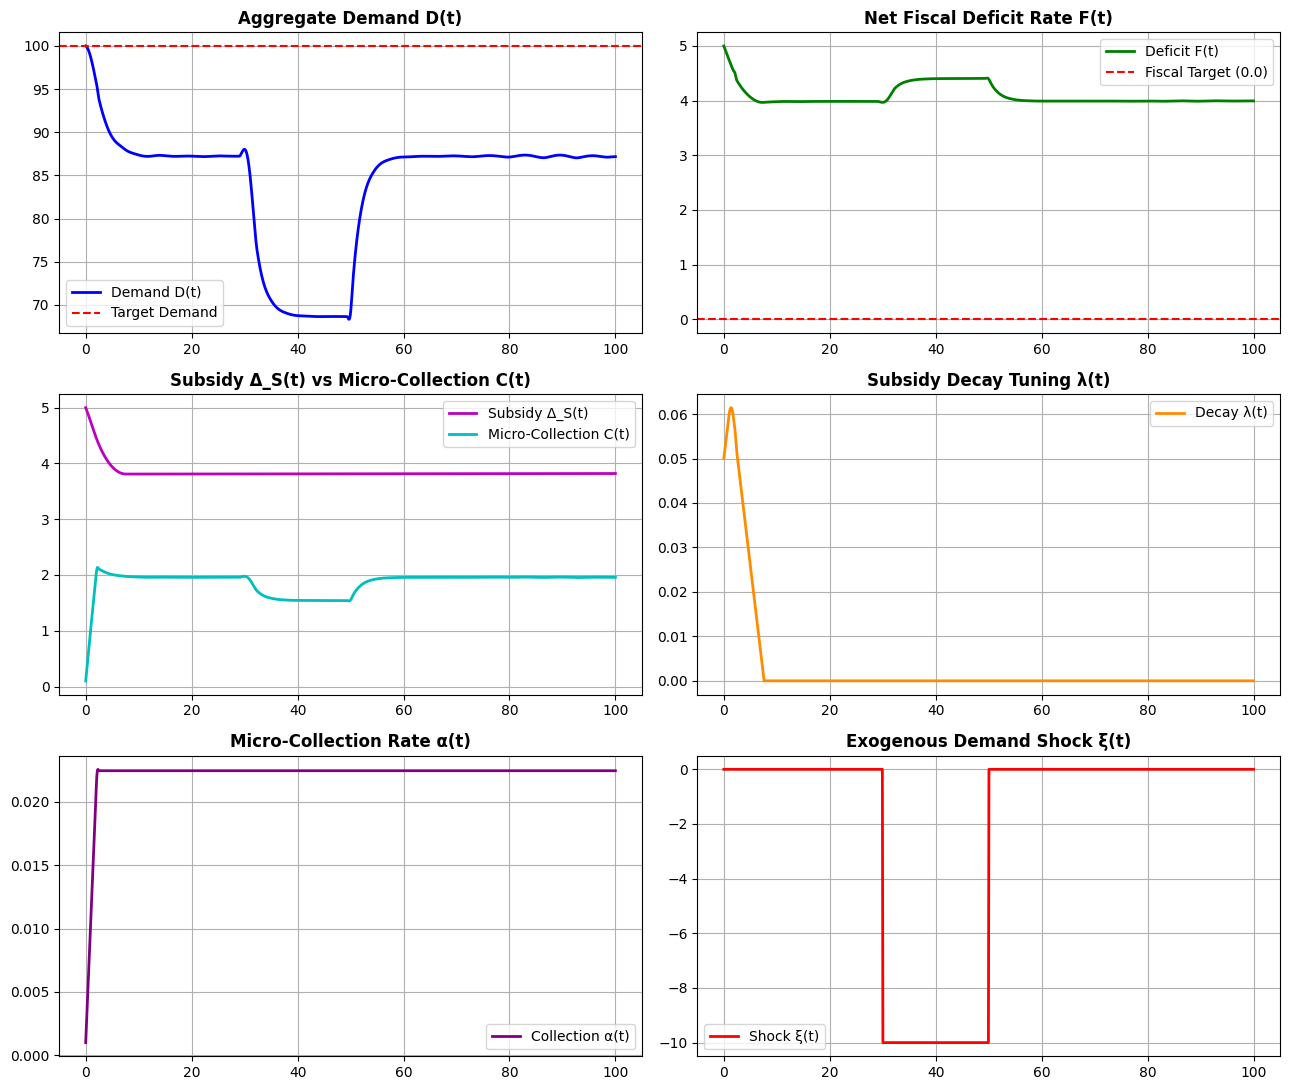

In [8]:
# Parse solution vectors
t = sol.t
D_sim, F_sim, Delta_S_sim, alpha_sim, lambda_sim = sol.y
C_sim = alpha_sim * D_sim

# Render 6-Panel Trajectory Plot
fig, axes = plt.subplots(3, 2, figsize=(13, 11))

# 1. Demand D(t)
axes[0, 0].plot(t, D_sim, 'b-', linewidth=2, label='Demand D(t)')
axes[0, 0].axhline(100.0, color='r', linestyle='--', label='Target Demand')
axes[0, 0].set_title('Aggregate Demand D(t)', fontweight='bold')
axes[0, 0].set_grid = True
axes[0, 0].grid(True)
axes[0, 0].legend()

# 2. Deficit F(t)
axes[0, 1].plot(t, F_sim, 'g-', linewidth=2, label='Deficit F(t)')
axes[0, 1].axhline(0.0, color='r', linestyle='--', label='Fiscal Target (0.0)')
axes[0, 1].set_title('Net Fiscal Deficit Rate F(t)', fontweight='bold')
axes[0, 1].grid(True)
axes[0, 1].legend()

# 3. Subsidy & Collection
axes[1, 0].plot(t, Delta_S_sim, 'm-', linewidth=2, label='Subsidy Δ_S(t)')
axes[1, 0].plot(t, C_sim, 'c-', linewidth=2, label='Micro-Collection C(t)')
axes[1, 0].set_title('Subsidy Δ_S(t) vs Micro-Collection C(t)', fontweight='bold')
axes[1, 0].grid(True)
axes[1, 0].legend()

# 4. Lambda Tuning
axes[1, 1].plot(t, lambda_sim, color='darkorange', linewidth=2, label='Decay λ(t)')
axes[1, 1].set_title('Subsidy Decay Tuning λ(t)', fontweight='bold')
axes[1, 1].grid(True)
axes[1, 1].legend()

# 5. Alpha Tuning
axes[2, 0].plot(t, alpha_sim, color='purple', linewidth=2, label='Collection α(t)')
axes[2, 0].set_title('Micro-Collection Rate α(t)', fontweight='bold')
axes[2, 0].grid(True)
axes[2, 0].legend()

# 6. Demand Shock Input
shock_profile = [-10.0 if 30 <= ti <= 50 else 0.0 for ti in t]
axes[2, 1].plot(t, shock_profile, 'r-', linewidth=2, label='Shock ξ(t)')
axes[2, 1].set_title('Exogenous Demand Shock ξ(t)', fontweight='bold')
axes[2, 1].grid(True)
axes[2, 1].legend()

plt.tight_layout()
plt.show()